# NGUYỄN THÀNH TRÍ - MSSV: 6451071079
## BÀI 3: PHÂN LỚP ẢNH CHỮ SỐ VIẾT TAY MNIST BẰNG NEURAL NETWORK KẾT HỢP 10-FOLD CROSS VALIDATION
### (K-FOLD CROSS VALIDATION VỚI K = 10)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import keras
from keras import layers, models

print("Đã nạp đầy đủ các thư viện cần thiết cho Bài 3.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


I0000 00:00:1794280021.947837   59588 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Đã nạp đầy đủ các thư viện cần thiết cho Bài 3.


I0000 00:00:1794280023.204125   59588 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Câu a: Đọc bộ dữ liệu train, test của MNIST từ Keras
Hướng dẫn: Sử dụng keras.datasets.mnist.load_data() để đọc dữ liệu ảnh và nhãn.

In [2]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()
print("Đã tải thành công bộ dữ liệu MNIST từ Keras.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Đã tải thành công bộ dữ liệu MNIST từ Keras.


### Câu b: In ra kích thước của tập train và test
Hướng dẫn: Sử dụng thuộc tính .shape của các mảng dữ liệu ảnh và nhãn.

In [3]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

print(f"Kích thước tập ảnh train: {train_images.shape}")
print(f"Kích thước tập nhãn train: {train_labels.shape}")
print(f"Kích thước tập ảnh test:  {test_images.shape}")
print(f"Kích thước tập nhãn test:  {test_labels.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập ảnh train: (60000, 28, 28)
Kích thước tập nhãn train: (60000,)
Kích thước tập ảnh test:  (10000, 28, 28)
Kích thước tập nhãn test:  (10000,)


### Câu c: Chuẩn hóa các giá trị pixel của ảnh về đoạn [0, 1]
Hướng dẫn: Chia các giá trị pixel cho 255.0 để đưa cường độ sáng về đoạn số thực [0, 1].

In [4]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

print(f"Giá trị pixel nhỏ nhất sau chuẩn hóa: {train_images.min():.1f}")
print(f"Giá trị pixel lớn nhất sau chuẩn hóa: {train_images.max():.1f}")
print(f"Kiểu dữ liệu của mảng ảnh: {train_images.dtype}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Giá trị pixel nhỏ nhất sau chuẩn hóa: 0.0
Giá trị pixel lớn nhất sau chuẩn hóa: 1.0
Kiểu dữ liệu của mảng ảnh: float32


### Câu d: Định nghĩa hàm create_model khởi tạo và biên dịch mạng Neural Network
Kiến trúc mô hình:
- Flatten layer: Làm phẳng ma trận 2D (28x28) thành vector 784 chiều.
- Dense layer: 128 nơ-ron, hàm kích hoạt ReLU.
- Dropout layer: Tỷ lệ 0.2.
- Dense layer (Output): 10 nơ-ron, hàm kích hoạt Softmax.
- Biên dịch với: optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'].

In [5]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def create_model():
    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Khởi tạo mô hình thử nghiệm và in cấu trúc
sample_model = create_model()
sample_model.summary()

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Câu e: Huấn luyện mô hình bằng K-Fold Cross Validation (k = 10)
Hướng dẫn:
- Sử dụng `KFold(n_splits=10, shuffle=True, random_state=42)`.
- Với mỗi fold:
  - Khởi tạo mô hình mới bằng `create_model()`.
  - Phân chia `X_train_fold, X_val_fold, y_train_fold, y_val_fold`.
  - Huấn luyện với `epochs=5`, `batch_size=32`, đánh giá trên tập validation.
  - Lưu mô hình vào danh sách `models`.
  - Tính và in loss, accuracy của từng fold, lưu vào `loss_per_fold` và `accuracy_per_fold`.

In [6]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

kfold = KFold(n_splits=10, shuffle=True, random_state=42)

models_list = []
accuracy_per_fold = []
loss_per_fold = []

print("Bắt đầu quá trình huấn luyện 10-Fold Cross Validation:")
print("-" * 65)

for fold_idx, (train_idx, val_idx) in enumerate(kfold.split(train_images), 1):
    X_train_fold, X_val_fold = train_images[train_idx], train_images[val_idx]
    y_train_fold, y_val_fold = train_labels[train_idx], train_labels[val_idx]

    model = create_model()
    model.fit(
        X_train_fold,
        y_train_fold,
        epochs=5,
        batch_size=32,
        validation_data=(X_val_fold, y_val_fold),
        verbose=0
    )

    val_loss, val_acc = model.evaluate(X_val_fold, y_val_fold, verbose=0)

    models_list.append(model)
    accuracy_per_fold.append(val_acc)
    loss_per_fold.append(val_loss)

    print(f"Fold {fold_idx:02d}/10 | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.4f} ({val_acc * 100:.2f}%)")

print("-" * 65)
print("Hoàn tất huấn luyện 10 folds.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Bắt đầu quá trình huấn luyện 10-Fold Cross Validation:
-----------------------------------------------------------------


Fold 01/10 | Validation Loss: 0.0743 | Validation Accuracy: 0.9768 (97.68%)


Fold 02/10 | Validation Loss: 0.0882 | Validation Accuracy: 0.9730 (97.30%)


Fold 03/10 | Validation Loss: 0.0851 | Validation Accuracy: 0.9747 (97.47%)


Fold 04/10 | Validation Loss: 0.0793 | Validation Accuracy: 0.9782 (97.82%)


Fold 05/10 | Validation Loss: 0.0937 | Validation Accuracy: 0.9740 (97.40%)


Fold 06/10 | Validation Loss: 0.0732 | Validation Accuracy: 0.9765 (97.65%)


Fold 07/10 | Validation Loss: 0.0923 | Validation Accuracy: 0.9738 (97.38%)


Fold 08/10 | Validation Loss: 0.0897 | Validation Accuracy: 0.9718 (97.18%)


Fold 09/10 | Validation Loss: 0.0882 | Validation Accuracy: 0.9720 (97.20%)


Fold 10/10 | Validation Loss: 0.0837 | Validation Accuracy: 0.9738 (97.38%)
-----------------------------------------------------------------
Hoàn tất huấn luyện 10 folds.


### Câu f: Tính và in Mean Accuracy, Std Accuracy, Mean Loss, Std Loss qua 10 fold
Hướng dẫn: Sử dụng hàm np.mean() và np.std() trên các mảng kết quả của 10 fold.

In [7]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

mean_acc = np.mean(accuracy_per_fold)
std_acc = np.std(accuracy_per_fold)
mean_loss = np.mean(loss_per_fold)
std_loss = np.std(loss_per_fold)

print("Kết quả thống kê qua 10 Fold Cross Validation:")
print(f"Độ chính xác trung bình (Mean Accuracy):               {mean_acc:.4f} ({mean_acc * 100:.2f}%)")
print(f"Độ lệch chuẩn độ chính xác (Std Deviation Accuracy):    {std_acc:.4f} ({std_acc * 100:.2f}%)")
print(f"Mất mát trung bình (Mean Loss):                         {mean_loss:.4f}")
print(f"Độ lệch chuẩn mất mát (Std Deviation Loss):             {std_loss:.4f}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kết quả thống kê qua 10 Fold Cross Validation:
Độ chính xác trung bình (Mean Accuracy):               0.9745 (97.45%)
Độ lệch chuẩn độ chính xác (Std Deviation Accuracy):    0.0020 (0.20%)
Mất mát trung bình (Mean Loss):                         0.0848
Độ lệch chuẩn mất mát (Std Deviation Loss):             0.0068


### Câu g: Vẽ biểu đồ thể hiện Accuracy và Loss sau mỗi fold
Hướng dẫn: Sử dụng `plt.plot` để trực quan hóa giá trị Accuracy và Loss qua 10 fold.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


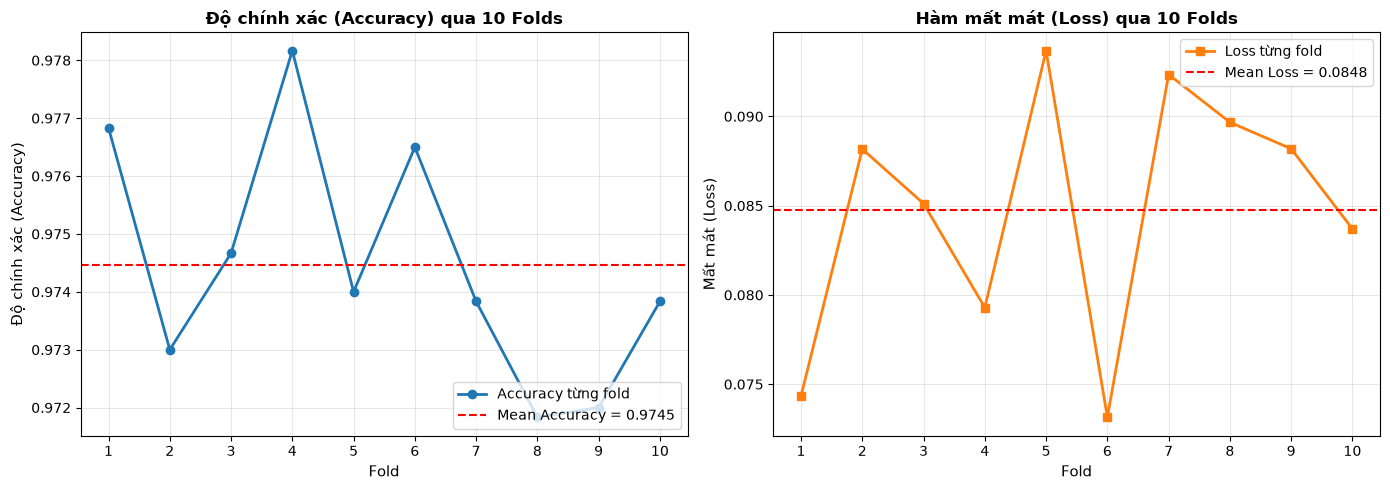

In [8]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

folds_range = range(1, 11)

plt.figure(figsize=(14, 5))

# Biểu đồ Accuracy qua các fold
plt.subplot(1, 2, 1)
plt.plot(folds_range, accuracy_per_fold, marker='o', color='#1f77b4', linewidth=2, label='Accuracy từng fold')
plt.axhline(y=mean_acc, color='red', linestyle='--', linewidth=1.5, label=f'Mean Accuracy = {mean_acc:.4f}')
plt.title('Độ chính xác (Accuracy) qua 10 Folds', fontsize=12, fontweight='bold')
plt.xlabel('Fold', fontsize=11)
plt.ylabel('Độ chính xác (Accuracy)', fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.grid(True, alpha=0.3)
plt.xticks(folds_range)

# Biểu đồ Loss qua các fold
plt.subplot(1, 2, 2)
plt.plot(folds_range, loss_per_fold, marker='s', color='#ff7f0e', linewidth=2, label='Loss từng fold')
plt.axhline(y=mean_loss, color='red', linestyle='--', linewidth=1.5, label=f'Mean Loss = {mean_loss:.4f}')
plt.title('Hàm mất mát (Loss) qua 10 Folds', fontsize=12, fontweight='bold')
plt.xlabel('Fold', fontsize=11)
plt.ylabel('Mất mát (Loss)', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, alpha=0.3)
plt.xticks(folds_range)

plt.tight_layout()
plt.show()

### Câu h: Tìm mô hình có Accuracy cao nhất giữa các fold trong quá trình huấn luyện
Hướng dẫn: Sử dụng `np.argmax(accuracy_per_fold)` để tìm chỉ số fold có độ chính xác cao nhất và trích xuất mô hình từ `models_list`.

In [9]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

best_fold_idx = int(np.argmax(accuracy_per_fold))
best_model = models_list[best_fold_idx]
best_acc = accuracy_per_fold[best_fold_idx]
best_loss = loss_per_fold[best_fold_idx]

print(f"Fold có kết quả tốt nhất: Fold {best_fold_idx + 1}")
print(f"Validation Accuracy:      {best_acc:.4f} ({best_acc * 100:.2f}%)")
print(f"Validation Loss:          {best_loss:.4f}")
print("Đã chọn mô hình từ Fold tốt nhất để đánh giá trên tập test.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Fold có kết quả tốt nhất: Fold 4
Validation Accuracy:      0.9782 (97.82%)
Validation Loss:          0.0793
Đã chọn mô hình từ Fold tốt nhất để đánh giá trên tập test.


### Câu i: Dùng mô hình tốt nhất tính và in Accuracy trên tập test
Hướng dẫn: Sử dụng mô hình tốt nhất để dự đoán trên tập test và tính độ chính xác bằng `accuracy_score`.

In [10]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

y_test_probs = best_model.predict(test_images, verbose=0)
y_test_pred = np.argmax(y_test_probs, axis=1)

test_accuracy = accuracy_score(test_labels, y_test_pred)
print(f"Độ chính xác (Accuracy) của mô hình tốt nhất trên tập test: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Độ chính xác (Accuracy) của mô hình tốt nhất trên tập test: 0.9754 (97.54%)


### Câu j: Tính và in Precision, Recall, F1-score của từng lớp và trung bình trên tập test
Hướng dẫn: Sử dụng `classification_report(test_labels, y_test_pred, digits=4)` từ sklearn.

In [11]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

target_names = [f"Chữ số {i}" for i in range(10)]
report = classification_report(test_labels, y_test_pred, target_names=target_names, digits=4)
print("Báo cáo chi tiết các độ đo đánh giá phân lớp trên tập test:")
print(report)

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Báo cáo chi tiết các độ đo đánh giá phân lớp trên tập test:
              precision    recall  f1-score   support

    Chữ số 0     0.9662    0.9929    0.9794       980
    Chữ số 1     0.9860    0.9912    0.9886      1135
    Chữ số 2     0.9832    0.9632    0.9731      1032
    Chữ số 3     0.9706    0.9822    0.9764      1010
    Chữ số 4     0.9776    0.9776    0.9776       982
    Chữ số 5     0.9896    0.9563    0.9726       892
    Chữ số 6     0.9800    0.9718    0.9759       958
    Chữ số 7     0.9635    0.9747    0.9691      1028
    Chữ số 8     0.9681    0.9651    0.9666       974
    Chữ số 9     0.9704    0.9752    0.9728      1009

    accuracy                         0.9754     10000
   macro avg     0.9755    0.9750    0.9752     10000
weighted avg     0.9755    0.9754    0.9754     10000



### Câu k: Hiển thị ma trận nhầm lẫn (Confusion Matrix) bằng bản đồ nhiệt (Heatmap) trên tập test
Hướng dẫn: Sử dụng `confusion_matrix` kết hợp với `sns.heatmap` để vẽ bản đồ nhiệt biểu diễn phân bố nhãn thực tế và dự đoán.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


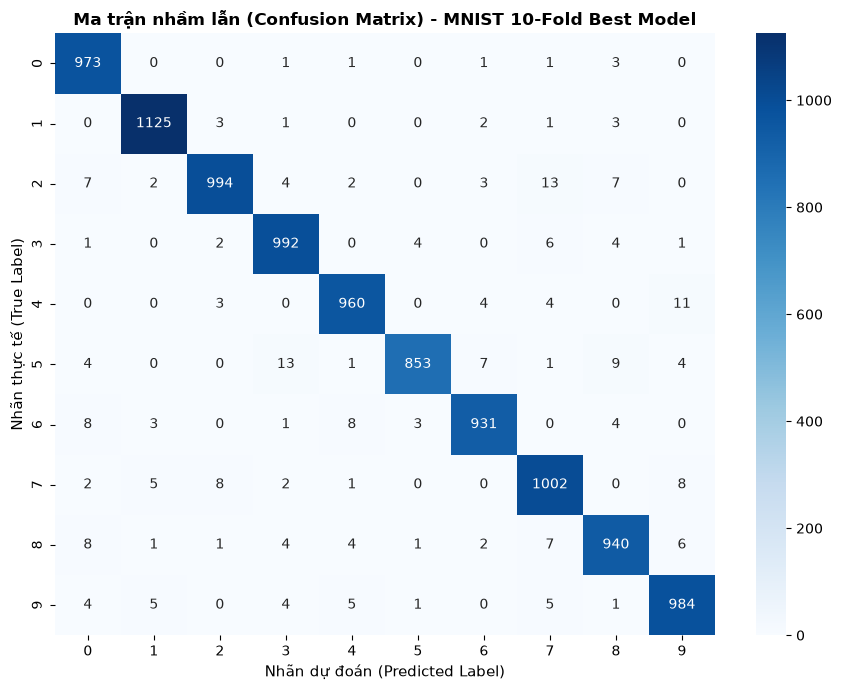

In [12]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

cm = confusion_matrix(test_labels, y_test_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title('Ma trận nhầm lẫn (Confusion Matrix) - MNIST 10-Fold Best Model', fontsize=12, fontweight='bold')
plt.xlabel('Nhãn dự đoán (Predicted Label)', fontsize=11)
plt.ylabel('Nhãn thực tế (True Label)', fontsize=11)
plt.tight_layout()
plt.show()

### Câu l: In kết quả phân lớp và hiển thị hình ảnh minh họa cho 5 ảnh đầu tiên trong tập test
Hướng dẫn: Dự đoán nhãn và xác suất cho 5 mẫu đầu tiên, hiển thị ảnh bằng `plt.imshow` kèm nhãn thực tế và nhãn dự đoán.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Ảnh 1: Nhãn thực tế = 7 | Nhãn dự đoán = 7 | Độ tin cậy = 99.99%


Ảnh 2: Nhãn thực tế = 2 | Nhãn dự đoán = 2 | Độ tin cậy = 99.99%
Ảnh 3: Nhãn thực tế = 1 | Nhãn dự đoán = 1 | Độ tin cậy = 99.90%
Ảnh 4: Nhãn thực tế = 0 | Nhãn dự đoán = 0 | Độ tin cậy = 100.00%
Ảnh 5: Nhãn thực tế = 4 | Nhãn dự đoán = 4 | Độ tin cậy = 99.32%


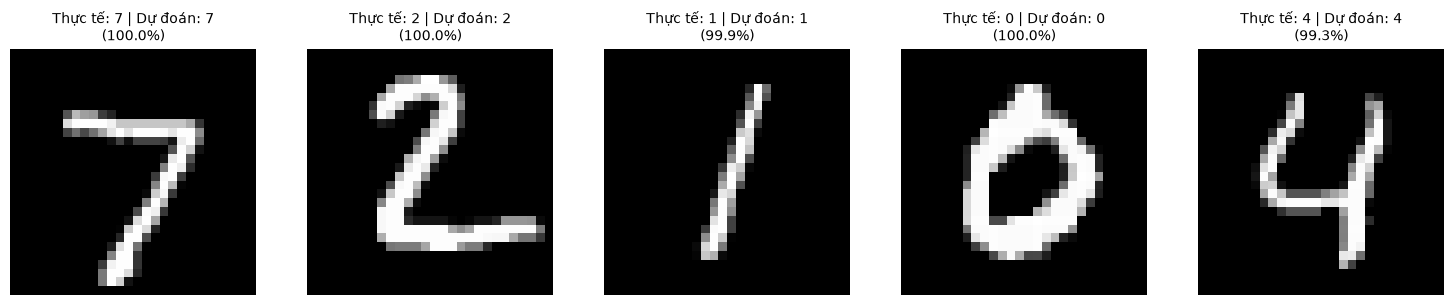

In [13]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

plt.figure(figsize=(15, 3))
for i in range(5):
    img = test_images[i]
    true_lbl = test_labels[i]
    img_input = np.expand_dims(img, axis=0)
    pred_prob = best_model.predict(img_input, verbose=0)
    pred_lbl = np.argmax(pred_prob)
    conf = pred_prob[0][pred_lbl] * 100

    print(f"Ảnh {i+1}: Nhãn thực tế = {true_lbl} | Nhãn dự đoán = {pred_lbl} | Độ tin cậy = {conf:.2f}%")

    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Thực tế: {true_lbl} | Dự đoán: {pred_lbl}\n({conf:.1f}%)", fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()